# STEP 22 — End-to-End BhumiGuard Integration

This notebook connects the verified structured-document pipeline to the
existing BhumiGuard ownership, validation, and risk modules.

The existing source package is inspected first so integration uses the
actual implemented API rather than assumed function names.

Synthetic records are used only in simulation/testing mode.
No live land transaction is created.

In [103]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(
    r"D:\BhumiGuard-BD"
)

SRC_DIR = (
    PROJECT_ROOT
    / "src"
)

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

print(
    "Source folder exists:",
    SRC_DIR.exists()
)

print(
    "Source path:",
    SRC_DIR
)

Source folder exists: True
Source path: D:\BhumiGuard-BD\src


In [104]:
import bhumiguard

from bhumiguard import (
    normalization,
    ledger,
    validation,
    risk,
)

print(
    "BhumiGuard imported successfully."
)

BhumiGuard imported successfully.


In [105]:
import inspect


def public_functions(module):

    return [
        name

        for name, obj
        in inspect.getmembers(
            module,
            inspect.isfunction
        )

        if not name.startswith("_")
    ]

## STEP 22C-FIX — Restore Verified Synthetic Record

The verified synthetic transaction fixture from STEP 21 is recreated
inside this notebook because notebook variables are not shared across
separate Jupyter notebooks.

This is test-only data and remains blocked from live transaction execution.

In [106]:
# Core helper functions needed by STEP 22 integration

TRANSACTION_CORE_FIELDS = [
    "deed_id",
    "execution_date",
    "seller_id",
    "buyer_id",
    "transferred_area",
]


def field_allowed_for_risk_engine(
    field_record
):
    return (
        field_record.get(
            "value"
        ) is not None
        and
        field_record.get(
            "verification_status"
        )
        in {
            "HUMAN_VERIFIED",
            "DERIVED_FROM_VERIFIED_FIELDS",
        }
    )


def verified_field_available(
    record,
    field_name
):
    field_record = (
        record[
            "fields"
        ][
            field_name
        ]
    )

    return field_allowed_for_risk_engine(
        field_record
    )


def verified_derived_field_available(
    record,
    field_name
):
    derived_fields = (
        record.get(
            "derived_fields",
            {}
        )
    )

    if field_name not in derived_fields:
        return False

    field_record = (
        derived_fields[
            field_name
        ]
    )

    return (
        field_record.get(
            "value"
        ) is not None
        and
        field_record.get(
            "verification_status"
        )
        ==
        "DERIVED_FROM_VERIFIED_FIELDS"
    )


def transaction_core_readiness(
    record
):
    missing_fields = []

    for field_name in (
        TRANSACTION_CORE_FIELDS
    ):

        if not verified_field_available(
            record,
            field_name
        ):
            missing_fields.append(
                field_name
            )

    parcel_key_ready = (
        verified_derived_field_available(
            record,
            "parcel_key"
        )
    )

    return {
        "ready":
            (
                len(
                    missing_fields
                ) == 0
                and
                parcel_key_ready
            ),

        "missing_fields":
            missing_fields,

        "parcel_key_ready":
            parcel_key_ready,
    }


def document_allowed_for_transaction_engine(
    record
):
    blocked_statuses = {
        "TEMPLATE_LIKE_UNFILLED",
        "NON_DEED",
        "OCR_UNVERIFIED",
        "SYNTHETIC_TEST_ONLY",
    }

    return (
        record[
            "document_status"
        ]
        not in blocked_statuses
    )

In [107]:
step21g_record = {
    "document_id":
        "synthetic_filled_property_test",

    "document_status":
        "SYNTHETIC_TEST_ONLY",

    "fields": {

        "deed_id": {
            "value":
                "DEED-SYN-001",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "execution_date": {
            "value":
                "2026-10-16",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "seller_id": {
            "value":
                "SELLER-SYN-001",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "buyer_id": {
            "value":
                "BUYER-SYN-001",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "transferred_area": {
            "value": {
                "amount":
                    "5.50",

                "unit":
                    "শতক",
            },

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "district": {
            "value":
                "নমুনা জেলা",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "upazila": {
            "value":
                "নমুনা উপজেলা",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "mouza": {
            "value":
                "নমুনা মৌজা",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "survey_type": {
            "value":
                "RS",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "khatian_no": {
            "value":
                "123",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },

        "dag_no": {
            "value":
                "456",

            "verification_status":
                "HUMAN_VERIFIED",

            "review_required":
                False,
        },
    },

    "derived_fields": {

        "parcel_key": {
            "value":
                (
                    "নমুনা জেলা|"
                    "নমুনা উপজেলা|"
                    "নমুনা মৌজা|"
                    "RS|123|456"
                ),

            "verification_status":
                "DERIVED_FROM_VERIFIED_FIELDS",

            "review_required":
                False,
        },

        "portion_id": {
            "value":
                None,

            "verification_status":
                "NOT_DERIVED",

            "review_required":
                True,
        },
    },
}

In [108]:
module_functions = {
    "normalization":
        public_functions(
            normalization
        ),

    "ledger":
        public_functions(
            ledger
        ),

    "validation":
        public_functions(
            validation
        ),

    "risk":
        public_functions(
            risk
        ),
}

for module_name, functions in (
    module_functions.items()
):

    print(
        "\n",
        module_name.upper()
    )

    print(
        "-" * 40
    )

    for function_name in functions:
        print(
            function_name
        )


 NORMALIZATION
----------------------------------------
bangla_to_english_digits
create_parcel_key
normalize_land_number
normalize_location
normalize_survey_type

 LEDGER
----------------------------------------
check_ledger_integrity
get_owner_area
next_ownership_id
process_transfer

 VALIDATION
----------------------------------------
check_deed_mutation_match
check_double_sale
check_duplicate_deed
process_transfer
process_transfer_full_checks

 RISK
----------------------------------------
calculate_risk_level
check_deed_mutation_match
check_double_sale
check_duplicate_deed
evaluate_transaction_rules
format_risk_report
get_owner_area
verify_transaction


In [109]:
for module_name, module in {
    "normalization": normalization,
    "ledger": ledger,
    "validation": validation,
    "risk": risk,
}.items():

    print(
        "\n",
        "=" * 60
    )

    print(
        module_name.upper()
    )

    print(
        "=" * 60
    )

    for name, obj in (
        inspect.getmembers(
            module,
            inspect.isfunction
        )
    ):

        if name.startswith("_"):
            continue

        print(
            name,
            inspect.signature(
                obj
            )
        )


NORMALIZATION
bangla_to_english_digits (value)
create_parcel_key (district, upazila, mouza, survey_type, khatian_no, dag_no)
normalize_land_number (value)
normalize_location (value)
normalize_survey_type (value)

LEDGER
check_ledger_integrity (ledger_df, parcels_df, tolerance=1e-09)
get_owner_area (ledger_df, parcel_id, owner_id)
next_ownership_id (ledger_df)
process_transfer (ledger_df, transaction, people_df, parcels_df)

VALIDATION
check_deed_mutation_match (mutation_df, transaction)
check_double_sale (history_df, transaction)
check_duplicate_deed (history_df, deed_id)
process_transfer (ledger_df, transaction, people_df, parcels_df)
process_transfer_full_checks (ledger_df, history_df, mutation_df, transaction, people_df, parcels_df)

RISK
calculate_risk_level (rules)
check_deed_mutation_match (mutation_df, transaction)
check_double_sale (history_df, transaction)
check_duplicate_deed (history_df, deed_id)
evaluate_transaction_rules (ledger_df, history_df, mutation_df, transaction, p

In [110]:
print(
    "normalization:",
    inspect.getfile(
        normalization
    )
)

print(
    "ledger:",
    inspect.getfile(
        ledger
    )
)

print(
    "validation:",
    inspect.getfile(
        validation
    )
)

print(
    "risk:",
    inspect.getfile(
        risk
    )
)

normalization: D:\BhumiGuard-BD\src\bhumiguard\normalization.py
ledger: D:\BhumiGuard-BD\src\bhumiguard\ledger.py
validation: D:\BhumiGuard-BD\src\bhumiguard\validation.py
risk: D:\BhumiGuard-BD\src\bhumiguard\risk.py


In [111]:
print("STEP 22A SUMMARY")
print("----------------")

print(
    "Normalization functions:",
    len(
        module_functions[
            "normalization"
        ]
    )
)

print(
    "Ledger functions:",
    len(
        module_functions[
            "ledger"
        ]
    )
)

print(
    "Validation functions:",
    len(
        module_functions[
            "validation"
        ]
    )
)

print(
    "Risk functions:",
    len(
        module_functions[
            "risk"
        ]
    )
)

print(
    "\nExisting BhumiGuard API Inspection: COMPLETE"
)

STEP 22A SUMMARY
----------------
Normalization functions: 5
Ledger functions: 4
Validation functions: 5
Risk functions: 8

Existing BhumiGuard API Inspection: COMPLETE


# STEP 22B — Existing Risk Engine Contract Inspection

Before connecting the verified extraction record to the BhumiGuard
risk engine, inspect the exact input contract already implemented in
the source modules.

Goals:

- identify transaction dictionary keys
- identify required ledger/history/mutation columns
- inspect the main verification flow
- avoid guessing field names during integration

In [112]:
for name, obj in inspect.getmembers(
    risk,
    inspect.isfunction
):
    if name.startswith("_"):
        continue

    print(
        name,
        inspect.signature(obj)
    )

calculate_risk_level (rules)
check_deed_mutation_match (mutation_df, transaction)
check_double_sale (history_df, transaction)
check_duplicate_deed (history_df, deed_id)
evaluate_transaction_rules (ledger_df, history_df, mutation_df, transaction, people_df, parcels_df)
format_risk_report (report)
get_owner_area (ledger_df, parcel_id, owner_id)
verify_transaction (ledger_df, history_df, mutation_df, transaction, people_df, parcels_df)


In [113]:
import re
import inspect


def transaction_keys_from_function(
    function
):

    source = inspect.getsource(
        function
    )

    bracket_keys = re.findall(
        r"""transaction\s*\[\s*['"]([^'"]+)['"]\s*\]""",
        source
    )

    get_keys = re.findall(
        r"""transaction\.get\(\s*['"]([^'"]+)['"]""",
        source
    )

    return sorted(
        set(
            bracket_keys
            + get_keys
        )
    )

In [114]:
functions_to_inspect = {
    "ledger.process_transfer":
        ledger.process_transfer,

    "validation.check_duplicate_deed":
        validation.check_duplicate_deed,

    "validation.check_double_sale":
        validation.check_double_sale,

    "validation.check_deed_mutation_match":
        validation.check_deed_mutation_match,

    "validation.process_transfer_full_checks":
        validation.process_transfer_full_checks,

    "risk.evaluate_transaction_rules":
        risk.evaluate_transaction_rules,

    "risk.verify_transaction":
        risk.verify_transaction,
}

In [115]:
transaction_contract = {}

for function_name, function in (
    functions_to_inspect.items()
):

    keys = (
        transaction_keys_from_function(
            function
        )
    )

    transaction_contract[
        function_name
    ] = keys

    print(
        "\n",
        function_name
    )

    print(
        "Transaction keys:",
        keys
    )


 ledger.process_transfer
Transaction keys: ['buyer_id', 'execution_date', 'parcel_id', 'seller_id', 'transferred_area_decimal']

 validation.check_duplicate_deed
Transaction keys: []

 validation.check_double_sale
Transaction keys: ['parcel_id', 'portion_id']

 validation.check_deed_mutation_match
Transaction keys: ['parcel_id', 'portion_id', 'seller_id']

 validation.process_transfer_full_checks
Transaction keys: ['deed_id', 'transaction_status']

 risk.evaluate_transaction_rules
Transaction keys: ['buyer_id', 'deed_id', 'parcel_id', 'seller_id', 'transferred_area_decimal']

 risk.verify_transaction
Transaction keys: ['buyer_id', 'deed_id', 'parcel_id', 'seller_id']


In [116]:
all_transaction_keys = sorted(
    {
        key

        for keys
        in transaction_contract.values()

        for key
        in keys
    }
)

print(
    "Combined transaction keys:",
    len(
        all_transaction_keys
    )
)

for key in all_transaction_keys:
    print(
        "-",
        key
    )

Combined transaction keys: 8
- buyer_id
- deed_id
- execution_date
- parcel_id
- portion_id
- seller_id
- transaction_status
- transferred_area_decimal


In [117]:
print(
    inspect.getsource(
        risk.verify_transaction
    )
)

def verify_transaction(
    ledger_df,
    history_df,
    mutation_df,
    transaction,
    people_df,
    parcels_df
):
    rules = evaluate_transaction_rules(
        ledger_df,
        history_df,
        mutation_df,
        transaction,
        people_df,
        parcels_df
    )

    summary = calculate_risk_level(
        rules
    )

    return {
        "deed_id":
            transaction["deed_id"],

        "parcel_id":
            transaction["parcel_id"],

        "seller_id":
            transaction["seller_id"],

        "buyer_id":
            transaction["buyer_id"],

        "risk_level":
            summary["risk_level"],

        "pass_count":
            summary["pass_count"],

        "warning_count":
            summary["warning_count"],

        "fail_count":
            summary["fail_count"],

        "rules":
            rules,

        "disclaimer":
            (
                "Screening result only. "
                "It does not establish legal title "
  

In [118]:
print(
    inspect.getsource(
        risk.evaluate_transaction_rules
    )
)

def evaluate_transaction_rules(
    ledger_df,
    history_df,
    mutation_df,
    transaction,
    people_df,
    parcels_df
):
    rules = {}

    seller_id = transaction["seller_id"]
    buyer_id = transaction["buyer_id"]
    parcel_id = transaction["parcel_id"]
    deed_id = transaction["deed_id"]

    transfer_area = float(
        transaction[
            "transferred_area_decimal"
        ]
    )

    person_ids = set(
        people_df["person_id"]
    )

    parcel_ids = set(
        parcels_df["parcel_id"]
    )

    # ---------------------------------
    # Rule 1: Deed ID
    # ---------------------------------

    duplicate_result = (
        check_duplicate_deed(
            history_df,
            deed_id
        )
    )

    if duplicate_result["duplicate"]:

        rules["deed_id_check"] = {
            "status": "FAIL",
            "code": "DUPLICATE_DEED",
            "message": (
                f"Deed ID {deed_id} "
                "already exists in the "
     

In [119]:
print(
    inspect.getsource(
        validation.process_transfer_full_checks
    )
)

def process_transfer_full_checks(
    ledger_df,
    history_df,
    mutation_df,
    transaction,
    people_df,
    parcels_df
):
    original_ledger = (
        ledger_df.copy(deep=True)
    )

    original_history = (
        history_df.copy(deep=True)
    )

    # ---------------------------------
    # 1. Duplicate deed
    # ---------------------------------

    duplicate_result = (
        check_duplicate_deed(
            history_df,
            transaction["deed_id"]
        )
    )

    if duplicate_result["duplicate"]:

        return (
            original_ledger,
            original_history,
            {
                "valid": False,
                "reason": "DUPLICATE_DEED",
                "existing_records":
                    duplicate_result[
                        "existing_records"
                    ],
            }
        )

    # ---------------------------------
    # 2. Double-sale
    # ---------------------------------

    double_sale_result = (
 

In [120]:
print(
    inspect.getsource(
        ledger.process_transfer
    )
)

def process_transfer(
    ledger_df,
    transaction,
    people_df,
    parcels_df
):
    original_ledger = (
        ledger_df.copy(deep=True)
    )

    updated_ledger = (
        ledger_df.copy(deep=True)
    )

    seller_id = transaction["seller_id"]
    buyer_id = transaction["buyer_id"]
    parcel_id = transaction["parcel_id"]

    transfer_area = float(
        transaction[
            "transferred_area_decimal"
        ]
    )

    person_ids = set(
        people_df["person_id"]
    )

    parcel_ids = set(
        parcels_df["parcel_id"]
    )

    # ---------------------------------
    # Basic validation
    # ---------------------------------

    if seller_id not in person_ids:

        return original_ledger, {
            "valid": False,
            "reason": "SELLER_NOT_FOUND"
        }

    if buyer_id not in person_ids:

        return original_ledger, {
            "valid": False,
            "reason": "BUYER_NOT_FOUND"
        }

    if parcel_id not in parcel_id

In [121]:
print(
    inspect.getsource(
        validation.check_duplicate_deed
    )
)

def check_duplicate_deed(
    history_df,
    deed_id
):
    matches = history_df[
        history_df["deed_id"] == deed_id
    ]

    if matches.empty:
        return {
            "duplicate": False,
            "reason": "DEED_ID_AVAILABLE"
        }

    return {
        "duplicate": True,
        "reason": "DUPLICATE_DEED",
        "existing_records": len(matches)
    }



In [122]:
print(
    inspect.getsource(
        validation.check_double_sale
    )
)

def check_double_sale(
    history_df,
    transaction
):
    portion_id = transaction.get(
        "portion_id"
    )

    if portion_id is None:
        return {
            "double_sale": False,
            "reason": "NO_PORTION_ID"
        }

    required_columns = {
        "parcel_id",
        "portion_id",
        "transaction_status",
        "deed_id",
        "buyer_id",
    }

    if not required_columns.issubset(
        history_df.columns
    ):
        return {
            "double_sale": False,
            "reason": "HISTORY_SCHEMA_INCOMPLETE"
        }

    previous_sales = history_df[
        (
            history_df["parcel_id"]
            == transaction["parcel_id"]
        )
        &
        (
            history_df["portion_id"]
            == portion_id
        )
        &
        (
            history_df[
                "transaction_status"
            ]
            == "VALID"
        )
    ]

    if previous_sales.empty:
        return {
            "double_sa

In [123]:
print(
    inspect.getsource(
        validation.check_deed_mutation_match
    )
)

def check_deed_mutation_match(
    mutation_df,
    transaction
):
    required_columns = {
        "parcel_id",
        "portion_id",
        "mutation_owner_id",
        "status",
    }

    if not required_columns.issubset(
        mutation_df.columns
    ):
        return {
            "match": None,
            "reason":
                "MUTATION_SCHEMA_INCOMPLETE"
        }

    records = mutation_df[
        (
            mutation_df["parcel_id"]
            == transaction["parcel_id"]
        )
        &
        (
            mutation_df["portion_id"]
            == transaction.get(
                "portion_id"
            )
        )
        &
        (
            mutation_df["status"]
            == "ACTIVE"
        )
    ]

    if records.empty:
        return {
            "match": None,
            "reason": "NO_MUTATION_RECORD"
        }

    mutation_owners = set(
        records[
            "mutation_owner_id"
        ]
    )

    deed_seller = transaction[
        "s

In [124]:
def quoted_tokens_from_function(
    function
):

    source = inspect.getsource(
        function
    )

    tokens = re.findall(
        r"""['"]([A-Za-z_][A-Za-z0-9_]*)['"]""",
        source
    )

    return sorted(
        set(tokens)
    )

In [125]:
for function_name, function in (
    functions_to_inspect.items()
):

    print(
        "\n",
        function_name
    )

    print(
        quoted_tokens_from_function(
            function
        )
    )


 ledger.process_transfer
['ACTIVE', 'BUYER_NOT_FOUND', 'INACTIVE', 'INSUFFICIENT_OWNERSHIP', 'INVALID_TRANSFER_AREA', 'LEDGER_INTEGRITY_FAILURE', 'PARCEL_NOT_FOUND', 'SELLER_BUYER_SAME', 'SELLER_NOT_FOUND', 'SELLER_NOT_OWNER', 'VALID_TRANSFER', 'buyer_id', 'execution_date', 'owned_area_decimal', 'owner_id', 'ownership_id', 'parcel_id', 'person_id', 'reason', 'requested_area', 'seller_available', 'seller_available_before', 'seller_id', 'status', 'transferred_area', 'transferred_area_decimal', 'valid', 'valid_from']

 validation.check_duplicate_deed
['DEED_ID_AVAILABLE', 'DUPLICATE_DEED', 'deed_id', 'duplicate', 'existing_records', 'reason']

 validation.check_double_sale
['DOUBLE_SALE', 'HISTORY_SCHEMA_INCOMPLETE', 'NO_PORTION_ID', 'NO_PREVIOUS_SALE', 'VALID', 'buyer_id', 'deed_id', 'double_sale', 'parcel_id', 'portion_id', 'previous_buyers', 'previous_deeds', 'reason', 'transaction_status']

 validation.check_deed_mutation_match
['ACTIVE', 'DEED_MUTATION_MISMATCH', 'MUTATION_MATCH', '

In [126]:
print(
    inspect.getsource(
        normalization.create_parcel_key
    )
)

def create_parcel_key(
    district,
    upazila,
    mouza,
    survey_type,
    khatian_no,
    dag_no
):
    district_n = normalize_location(
        district
    )

    upazila_n = normalize_location(
        upazila
    )

    mouza_n = normalize_location(
        mouza
    )

    survey_n = normalize_survey_type(
        survey_type
    )

    khatian_n = normalize_land_number(
        khatian_no
    )

    dag_n = normalize_land_number(
        dag_no
    )

    components = [
        district_n,
        upazila_n,
        mouza_n,
        survey_n,
        khatian_n,
        dag_n,
    ]

    if any(
        value is None
        for value in components
    ):
        return None

    return "|".join(
        components
    )



In [127]:
print(
    inspect.getsource(
        normalization.normalize_land_number
    )
)

def normalize_land_number(value):
    if value is None:
        return None

    value = bangla_to_english_digits(
        value
    )

    value = unicodedata.normalize(
        "NFKC",
        value
    )

    value = value.strip()

    labels = [
        "দাগ নং",
        "দাগ নম্বর",
        "দাগ",
        "খতিয়ান নং",
        "খতিয়ান নং",
        "খতিয়ান নম্বর",
        "খতিয়ান নম্বর",
        "খতিয়ান",
        "খতিয়ান",
        "নং",
        "নম্বর",
        "NO.",
        "NO",
    ]

    for label in labels:
        value = value.replace(
            label,
            ""
        )

    value = value.strip()

    digits = re.sub(
        r"[^0-9]",
        "",
        value
    )

    if digits == "":
        return None

    return str(
        int(digits)
    )



In [128]:
print("STEP 22B SUMMARY")
print("----------------")

print(
    "Functions inspected:",
    len(
        functions_to_inspect
    )
)

print(
    "Combined transaction keys:",
    len(
        all_transaction_keys
    )
)

print(
    "Risk verification API:",
    str(
        inspect.signature(
            risk.verify_transaction
        )
    )
)

print(
    "Risk evaluation API:",
    str(
        inspect.signature(
            risk.evaluate_transaction_rules
        )
    )
)

print(
    "\nExisting Engine Contract Inspection: COMPLETE"
)

STEP 22B SUMMARY
----------------
Functions inspected: 7
Combined transaction keys: 8
Risk verification API: (ledger_df, history_df, mutation_df, transaction, people_df, parcels_df)
Risk evaluation API: (ledger_df, history_df, mutation_df, transaction, people_df, parcels_df)

Existing Engine Contract Inspection: COMPLETE


# STEP 22C — Verified Extraction to BhumiGuard Transaction Adapter

This step converts a verified structured extraction record into the exact
transaction dictionary required by the existing BhumiGuard backend.

Safety rules:

- only verified fields are accepted
- ParcelKey must already be derived from verified parcel fields
- parcel_id must be resolved from the parcel registry
- transferred area must be converted to a numeric decimal value
- portion_id remains optional and is never fabricated
- synthetic test documents remain blocked from live execution

In [129]:
ENGINE_TRANSACTION_KEYS = [
    "buyer_id",
    "deed_id",
    "execution_date",
    "parcel_id",
    "portion_id",
    "seller_id",
    "transaction_status",
    "transferred_area_decimal",
]

print(
    "Engine transaction keys:",
    len(ENGINE_TRANSACTION_KEYS)
)

Engine transaction keys: 8


In [130]:
def get_verified_value(
    record,
    field_name
):
    field_record = (
        record[
            "fields"
        ][
            field_name
        ]
    )

    if not field_allowed_for_risk_engine(
        field_record
    ):
        return None

    return field_record[
        "value"
    ]

In [131]:
print(
    "Seller:",
    get_verified_value(
        step21g_record,
        "seller_id"
    )
)

print(
    "Buyer:",
    get_verified_value(
        step21g_record,
        "buyer_id"
    )
)

Seller: SELLER-SYN-001
Buyer: BUYER-SYN-001


In [132]:
print(
    "Record restored:",
    step21g_record[
        "document_id"
    ]
)

print(
    "Status:",
    step21g_record[
        "document_status"
    ]
)

print(
    "Transaction core:",
    transaction_core_readiness(
        step21g_record
    )
)

print(
    "ParcelKey:",
    step21g_record[
        "derived_fields"
    ][
        "parcel_key"
    ][
        "value"
    ]
)

print(
    "Portion ID:",
    step21g_record[
        "derived_fields"
    ][
        "portion_id"
    ][
        "value"
    ]
)

print(
    "Live execution allowed:",
    document_allowed_for_transaction_engine(
        step21g_record
    )
)

Record restored: synthetic_filled_property_test
Status: SYNTHETIC_TEST_ONLY
Transaction core: {'ready': True, 'missing_fields': [], 'parcel_key_ready': True}
ParcelKey: নমুনা জেলা|নমুনা উপজেলা|নমুনা মৌজা|RS|123|456
Portion ID: None
Live execution allowed: False


In [133]:
print(
    "Seller:",
    get_verified_value(
        step21g_record,
        "seller_id"
    )
)

print(
    "Buyer:",
    get_verified_value(
        step21g_record,
        "buyer_id"
    )
)

Seller: SELLER-SYN-001
Buyer: BUYER-SYN-001


In [134]:
{
    "amount": "5.50",
    "unit": "শতক"
}

{'amount': '5.50', 'unit': 'শতক'}

In [135]:
def verified_area_to_decimal(
    record,
    field_name
):
    value = get_verified_value(
        record,
        field_name
    )

    if value is None:
        return None

    if not isinstance(
        value,
        dict
    ):
        raise ValueError(
            f"{field_name} must contain "
            "an amount/unit dictionary."
        )

    amount = value.get(
        "amount"
    )

    unit = value.get(
        "unit"
    )

    if amount is None:
        return None

    if unit not in {
        "শতক",
        "ডেসিমেল",
    }:
        raise ValueError(
            f"Unsupported area unit "
            f"for current engine adapter: {unit}"
        )

    return float(
        amount
    )

In [136]:
transferred_area_decimal = (
    verified_area_to_decimal(
        step21g_record,
        "transferred_area"
    )
)

print(
    "Transferred area decimal:",
    transferred_area_decimal
)

Transferred area decimal: 5.5


In [137]:
def get_verified_parcel_key(
    record
):
    derived_fields = (
        record.get(
            "derived_fields",
            {}
        )
    )

    parcel_record = (
        derived_fields.get(
            "parcel_key"
        )
    )

    if parcel_record is None:
        return None

    if (
        parcel_record.get(
            "verification_status"
        )
        !=
        "DERIVED_FROM_VERIFIED_FIELDS"
    ):
        return None

    return parcel_record.get(
        "value"
    )

In [138]:
verified_parcel_key = (
    get_verified_parcel_key(
        step21g_record
    )
)

print(
    "Verified ParcelKey:",
    verified_parcel_key
)

Verified ParcelKey: নমুনা জেলা|নমুনা উপজেলা|নমুনা মৌজা|RS|123|456


In [139]:
def resolve_parcel_id(
    parcels_df,
    parcel_key
):
    if parcel_key is None:
        return None

    required_columns = {
        "parcel_id",
        "parcel_key",
    }

    if not required_columns.issubset(
        parcels_df.columns
    ):
        raise ValueError(
            "parcels_df must contain "
            "'parcel_id' and 'parcel_key'."
        )

    matches = (
        parcels_df[
            parcels_df[
                "parcel_key"
            ]
            ==
            parcel_key
        ]
    )

    if len(matches) == 0:
        return None

    if len(matches) > 1:
        raise ValueError(
            "ParcelKey maps to multiple parcel IDs."
        )

    return matches.iloc[0][
        "parcel_id"
    ]

In [140]:
import pandas as pd
import numpy as np
import re
import inspect
import sys

from copy import deepcopy
from pathlib import Path

print("Core imports: READY")

Core imports: READY


In [141]:
print(
    "Pandas version:",
    pd.__version__
)

Pandas version: 3.0.6


In [142]:
adapter_test_parcels_df = (
    pd.DataFrame(
        [
            {
                "parcel_id":
                    "PARCEL-SYN-001",

                "parcel_key":
                    verified_parcel_key,
            }
        ]
    )
)

adapter_test_parcels_df

,parcel_id,parcel_key
0,PARCEL-SYN-001,নমুনা জেলা|নমুনা উপজেলা|নমুনা মৌজা|RS|123|456


In [143]:
resolved_parcel_id = (
    resolve_parcel_id(
        adapter_test_parcels_df,
        verified_parcel_key
    )
)

print(
    "Resolved parcel ID:",
    resolved_parcel_id
)

Resolved parcel ID: PARCEL-SYN-001


In [144]:
def get_verified_portion_id(
    record
):
    derived_fields = (
        record.get(
            "derived_fields",
            {}
        )
    )

    portion_record = (
        derived_fields.get(
            "portion_id"
        )
    )

    if portion_record is None:
        return None

    if (
        portion_record.get(
            "verification_status"
        )
        !=
        "DERIVED_FROM_VERIFIED_FIELDS"
    ):
        return None

    return portion_record.get(
        "value"
    )

In [145]:
verified_portion_id = (
    get_verified_portion_id(
        step21g_record
    )
)

print(
    "Verified portion ID:",
    verified_portion_id
)

Verified portion ID: None


In [146]:
def build_bhumiguard_transaction(
    record,
    parcels_df,
    transaction_status="PENDING"
):
    readiness = (
        transaction_core_readiness(
            record
        )
    )

    if not readiness[
        "ready"
    ]:
        raise ValueError(
            "Transaction-core verified evidence "
            "is incomplete."
        )

    parcel_key = (
        get_verified_parcel_key(
            record
        )
    )

    parcel_id = (
        resolve_parcel_id(
            parcels_df,
            parcel_key
        )
    )

    if parcel_id is None:
        raise ValueError(
            "Verified ParcelKey was not found "
            "in the parcel registry."
        )

    transaction = {
        "buyer_id":
            get_verified_value(
                record,
                "buyer_id"
            ),

        "deed_id":
            get_verified_value(
                record,
                "deed_id"
            ),

        "execution_date":
            get_verified_value(
                record,
                "execution_date"
            ),

        "parcel_id":
            parcel_id,

        "portion_id":
            get_verified_portion_id(
                record
            ),

        "seller_id":
            get_verified_value(
                record,
                "seller_id"
            ),

        "transaction_status":
            transaction_status,

        "transferred_area_decimal":
            verified_area_to_decimal(
                record,
                "transferred_area"
            ),
    }

    return transaction

In [147]:
step22c_transaction = (
    build_bhumiguard_transaction(
        step21g_record,
        adapter_test_parcels_df
    )
)

step22c_transaction

{'buyer_id': 'BUYER-SYN-001',
 'deed_id': 'DEED-SYN-001',
 'execution_date': '2026-10-16',
 'parcel_id': 'PARCEL-SYN-001',
 'portion_id': None,
 'seller_id': 'SELLER-SYN-001',
 'transaction_status': 'PENDING',
 'transferred_area_decimal': 5.5}

In [148]:
{
    "buyer_id": "BUYER-SYN-001",
    "deed_id": "DEED-SYN-001",
    "execution_date": "2026-10-16",
    "parcel_id": "PARCEL-SYN-001",
    "portion_id": None,
    "seller_id": "SELLER-SYN-001",
    "transaction_status": "PENDING",
    "transferred_area_decimal": 5.5,
}

{'buyer_id': 'BUYER-SYN-001',
 'deed_id': 'DEED-SYN-001',
 'execution_date': '2026-10-16',
 'parcel_id': 'PARCEL-SYN-001',
 'portion_id': None,
 'seller_id': 'SELLER-SYN-001',
 'transaction_status': 'PENDING',
 'transferred_area_decimal': 5.5}

In [149]:
actual_transaction_keys = set(
    step22c_transaction.keys()
)

expected_transaction_keys = set(
    ENGINE_TRANSACTION_KEYS
)

print(
    "Missing engine keys:",
    sorted(
        expected_transaction_keys
        -
        actual_transaction_keys
    )
)

print(
    "Unexpected engine keys:",
    sorted(
        actual_transaction_keys
        -
        expected_transaction_keys
    )
)

Missing engine keys: []
Unexpected engine keys: []


In [150]:
adapter_source_fields = [
    "buyer_id",
    "deed_id",
    "execution_date",
    "seller_id",
    "transferred_area",
]

adapter_unverified_sources = [
    field_name

    for field_name
    in adapter_source_fields

    if not verified_field_available(
        step21g_record,
        field_name
    )
]

print(
    "Unverified adapter source fields:",
    adapter_unverified_sources
)

Unverified adapter source fields: []


In [151]:
print(
    "Engine portion_id:",
    step22c_transaction[
        "portion_id"
    ]
)

double_sale_adapter_check = (
    validation.check_double_sale(
        pd.DataFrame(
            columns=[
                "parcel_id",
                "portion_id",
                "transaction_status",
                "deed_id",
                "buyer_id",
            ]
        ),
        step22c_transaction
    )
)

double_sale_adapter_check

Engine portion_id: None


{'double_sale': False, 'reason': 'NO_PORTION_ID'}

In [152]:
step22c_document_permission = (
    document_allowed_for_transaction_engine(
        step21g_record
    )
)

print(
    "Transaction object built:",
    step22c_transaction
    is not None
)

print(
    "Live execution allowed:",
    step22c_document_permission
)

Transaction object built: True
Live execution allowed: False


In [153]:
assert (
    actual_transaction_keys
    ==
    expected_transaction_keys
)

assert (
    adapter_unverified_sources
    == []
)

assert (
    step22c_transaction[
        "parcel_id"
    ]
    ==
    "PARCEL-SYN-001"
)

assert (
    step22c_transaction[
        "transferred_area_decimal"
    ]
    ==
    5.5
)

assert (
    step22c_transaction[
        "portion_id"
    ]
    is None
)

assert (
    double_sale_adapter_check[
        "reason"
    ]
    ==
    "NO_PORTION_ID"
)

assert (
    step22c_document_permission
    is False
)

print(
    "BhumiGuard transaction adapter tests: PASS"
)

BhumiGuard transaction adapter tests: PASS


In [154]:
print("STEP 22C SUMMARY")
print("----------------")

print(
    "Engine keys required:",
    len(
        ENGINE_TRANSACTION_KEYS
    )
)

print(
    "Engine keys generated:",
    len(
        step22c_transaction
    )
)

print(
    "Missing engine keys:",
    len(
        expected_transaction_keys
        -
        actual_transaction_keys
    )
)

print(
    "Verified ParcelKey resolved:",
    resolved_parcel_id
    is not None
)

print(
    "Transferred area decimal:",
    step22c_transaction[
        "transferred_area_decimal"
    ]
)

print(
    "Portion ID available:",
    step22c_transaction[
        "portion_id"
    ]
    is not None
)

print(
    "Double-sale adapter result:",
    double_sale_adapter_check[
        "reason"
    ]
)

print(
    "Unverified source fields used:",
    len(
        adapter_unverified_sources
    )
)

print(
    "Live execution allowed:",
    step22c_document_permission
)

print(
    "\nVerified Record → BhumiGuard Adapter: PASS"
)

STEP 22C SUMMARY
----------------
Engine keys required: 8
Engine keys generated: 8
Missing engine keys: 0
Verified ParcelKey resolved: True
Transferred area decimal: 5.5
Portion ID available: False
Double-sale adapter result: NO_PORTION_ID
Unverified source fields used: 0
Live execution allowed: False

Verified Record → BhumiGuard Adapter: PASS


# STEP 22D — Risk Engine DataFrame Contract

Identify the exact dataframe columns used by the existing BhumiGuard
risk engine before constructing the end-to-end synthetic test context.

This prevents schema assumptions and keeps integration consistent with
the already validated backend.

In [155]:
import inspect
import re


def extract_dataframe_columns(
    module,
    dataframe_name
):
    source = inspect.getsource(
        module
    )

    pattern = (
        rf'{dataframe_name}'
        rf'\s*\[\s*["\']([^"\']+)["\']\s*\]'
    )

    return sorted(
        set(
            re.findall(
                pattern,
                source
            )
        )
    )

In [156]:
dataframe_contract = {
    "ledger_df":
        sorted(
            set(
                extract_dataframe_columns(
                    ledger,
                    "ledger_df"
                )
                +
                extract_dataframe_columns(
                    validation,
                    "ledger_df"
                )
                +
                extract_dataframe_columns(
                    risk,
                    "ledger_df"
                )
            )
        ),

    "history_df":
        sorted(
            set(
                extract_dataframe_columns(
                    validation,
                    "history_df"
                )
                +
                extract_dataframe_columns(
                    risk,
                    "history_df"
                )
            )
        ),

    "mutation_df":
        sorted(
            set(
                extract_dataframe_columns(
                    validation,
                    "mutation_df"
                )
                +
                extract_dataframe_columns(
                    risk,
                    "mutation_df"
                )
            )
        ),

    "people_df":
        sorted(
            set(
                extract_dataframe_columns(
                    ledger,
                    "people_df"
                )
                +
                extract_dataframe_columns(
                    validation,
                    "people_df"
                )
                +
                extract_dataframe_columns(
                    risk,
                    "people_df"
                )
            )
        ),

    "parcels_df":
        sorted(
            set(
                extract_dataframe_columns(
                    ledger,
                    "parcels_df"
                )
                +
                extract_dataframe_columns(
                    validation,
                    "parcels_df"
                )
                +
                extract_dataframe_columns(
                    risk,
                    "parcels_df"
                )
            )
        ),
}

In [157]:
for dataframe_name, columns in (
    dataframe_contract.items()
):

    print(
        "\n",
        dataframe_name.upper()
    )

    print(
        "-" * 45
    )

    print(
        "Columns:",
        len(columns)
    )

    for column in columns:
        print(
            "-",
            column
        )


 LEDGER_DF
---------------------------------------------
Columns: 5
- owned_area_decimal
- owner_id
- ownership_id
- parcel_id
- status

 HISTORY_DF
---------------------------------------------
Columns: 4
- deed_id
- parcel_id
- portion_id
- transaction_status

 MUTATION_DF
---------------------------------------------
Columns: 3
- parcel_id
- portion_id
- status

 PEOPLE_DF
---------------------------------------------
Columns: 1
- person_id

 PARCELS_DF
---------------------------------------------
Columns: 1
- parcel_id


In [158]:
def show_required_column_sets(
    function
):
    source = inspect.getsource(
        function
    )

    matches = re.findall(
        r'required_columns\s*=\s*\{([^}]+)\}',
        source,
        flags=re.DOTALL
    )

    return matches

In [159]:
important_functions = {
    "check_double_sale":
        validation.check_double_sale,

    "check_deed_mutation_match":
        validation.check_deed_mutation_match,

    "process_transfer":
        ledger.process_transfer,

    "evaluate_transaction_rules":
        risk.evaluate_transaction_rules,
}

for name, function in (
    important_functions.items()
):

    print(
        "\n",
        name
    )

    print(
        show_required_column_sets(
            function
        )
    )


 check_double_sale
['\n        "parcel_id",\n        "portion_id",\n        "transaction_status",\n        "deed_id",\n        "buyer_id",\n    ']

 check_deed_mutation_match
['\n        "parcel_id",\n        "portion_id",\n        "mutation_owner_id",\n        "status",\n    ']

 process_transfer
[]

 evaluate_transaction_rules
[]


In [160]:
print("STEP 22D SUMMARY")
print("----------------")

for name, columns in (
    dataframe_contract.items()
):

    print(
        f"{name}:",
        len(columns),
        "columns"
    )

print(
    "\nRisk Engine DataFrame Contract: COMPLETE"
)

STEP 22D SUMMARY
----------------
ledger_df: 5 columns
history_df: 4 columns
mutation_df: 3 columns
people_df: 1 columns
parcels_df: 1 columns

Risk Engine DataFrame Contract: COMPLETE


# STEP 22E — First End-to-End BhumiGuard Risk Report

Run the verified synthetic transaction through the existing BhumiGuard
risk engine.

This is simulation-only:

- no live transaction is committed
- the seller has sufficient ownership
- no previous deed exists
- no portion_id is available
- mutation evidence is intentionally absent

The goal is to verify complete integration from structured extraction
to an explainable risk report.

In [161]:
people_df = pd.DataFrame(
    [
        {
            "person_id":
                "SELLER-SYN-001"
        },
        {
            "person_id":
                "BUYER-SYN-001"
        },
    ]
)

people_df

,person_id
0,SELLER-SYN-001
1,BUYER-SYN-001


In [162]:
parcels_df = pd.DataFrame(
    [
        {
            "parcel_id":
                "PARCEL-SYN-001"
        }
    ]
)

parcels_df

,parcel_id
0,PARCEL-SYN-001


In [163]:
ledger_df = pd.DataFrame(
    [
        {
            "ownership_id":
                "OWN-SYN-001",

            "parcel_id":
                "PARCEL-SYN-001",

            "owner_id":
                "SELLER-SYN-001",

            "owned_area_decimal":
                10.50,

            "status":
                "ACTIVE",
        }
    ]
)

ledger_df

,ownership_id,parcel_id,owner_id,owned_area_decimal,status
0,OWN-SYN-001,PARCEL-SYN-001,SELLER-SYN-001,10.5,ACTIVE


In [164]:
history_df = pd.DataFrame(
    columns=[
        "deed_id",
        "parcel_id",
        "portion_id",
        "transaction_status",
        "buyer_id",
    ]
)

history_df

,deed_id,parcel_id,portion_id,transaction_status,buyer_id


In [165]:
mutation_df = pd.DataFrame(
    columns=[
        "parcel_id",
        "portion_id",
        "mutation_owner_id",
        "status",
    ]
)

mutation_df

,parcel_id,portion_id,mutation_owner_id,status


In [166]:
step22e_transaction = (
    step22c_transaction.copy()
)

step22e_transaction

{'buyer_id': 'BUYER-SYN-001',
 'deed_id': 'DEED-SYN-001',
 'execution_date': '2026-10-16',
 'parcel_id': 'PARCEL-SYN-001',
 'portion_id': None,
 'seller_id': 'SELLER-SYN-001',
 'transaction_status': 'PENDING',
 'transferred_area_decimal': 5.5}

In [167]:
seller_owned_area = (
    ledger.get_owner_area(
        ledger_df,
        "PARCEL-SYN-001",
        "SELLER-SYN-001"
    )
)

print(
    "Seller current ownership:",
    seller_owned_area
)

print(
    "Requested transfer:",
    step22e_transaction[
        "transferred_area_decimal"
    ]
)

Seller current ownership: 10.5
Requested transfer: 5.5


In [168]:
step22e_risk_report = (
    risk.verify_transaction(
        ledger_df,
        history_df,
        mutation_df,
        step22e_transaction,
        people_df,
        parcels_df,
    )
)

step22e_risk_report

{'deed_id': 'DEED-SYN-001',
 'parcel_id': 'PARCEL-SYN-001',
 'seller_id': 'SELLER-SYN-001',
 'buyer_id': 'BUYER-SYN-001',
 'risk_level': 'MEDIUM',
 'pass_count': 6,
 'warning_count': 2,
 'fail_count': 0,
 'rules': {'deed_id_check': {'status': 'PASS',
   'code': 'DEED_ID_AVAILABLE',
   'message': 'Deed ID is not duplicated.'},
  'seller_reference_check': {'status': 'PASS',
   'code': 'SELLER_FOUND',
   'message': 'Seller exists in the registry.'},
  'buyer_reference_check': {'status': 'PASS',
   'code': 'BUYER_FOUND',
   'message': 'Buyer exists and differs from the seller.'},
  'parcel_check': {'status': 'PASS',
   'code': 'PARCEL_FOUND',
   'message': 'Parcel exists in the registry.'},
  'seller_ownership_check': {'status': 'PASS',
   'code': 'SELLER_IS_OWNER',
   'message': 'Seller currently owns 10.5 decimal in the parcel.'},
  'area_check': {'status': 'PASS',
   'code': 'AREA_AVAILABLE',
   'message': 'Requested transfer of 5.5 decimal is within seller ownership.'},
  'double_sale_

In [169]:
print(
    "Deed:",
    step22e_risk_report[
        "deed_id"
    ]
)

print(
    "Parcel:",
    step22e_risk_report[
        "parcel_id"
    ]
)

print(
    "Seller:",
    step22e_risk_report[
        "seller_id"
    ]
)

print(
    "Buyer:",
    step22e_risk_report[
        "buyer_id"
    ]
)

print(
    "Risk level:",
    step22e_risk_report[
        "risk_level"
    ]
)

print(
    "PASS:",
    step22e_risk_report[
        "pass_count"
    ]
)

print(
    "WARNING:",
    step22e_risk_report[
        "warning_count"
    ]
)

print(
    "FAIL:",
    step22e_risk_report[
        "fail_count"
    ]
)

Deed: DEED-SYN-001
Parcel: PARCEL-SYN-001
Seller: SELLER-SYN-001
Buyer: BUYER-SYN-001
Risk level: MEDIUM
PASS: 6
FAIL: 0


In [170]:
step22e_rules_df = pd.DataFrame(
    step22e_risk_report[
        "rules"
    ]
)

step22e_rules_df

,deed_id_check,seller_reference_check,buyer_reference_check,parcel_check,seller_ownership_check,area_check,double_sale_check,mutation_check
status,PASS,PASS,PASS,PASS,PASS,PASS,WARNING,WARNING
code,DEED_ID_AVAILABLE,SELLER_FOUND,BUYER_FOUND,PARCEL_FOUND,SELLER_IS_OWNER,AREA_AVAILABLE,PORTION_ID_UNAVAILABLE,NO_MUTATION_RECORD
message,Deed ID is not duplicated.,Seller exists in the registry.,Buyer exists and differs from the seller.,Parcel exists in the registry.,Seller currently owns 10.5 decimal in the parcel.,Requested transfer of 5.5 decimal is within se...,Double-sale verification is incomplete because...,No matching mutation record is available for t...


In [171]:
step22e_risk_report[
    "rules"
]

{'deed_id_check': {'status': 'PASS',
  'code': 'DEED_ID_AVAILABLE',
  'message': 'Deed ID is not duplicated.'},
 'seller_reference_check': {'status': 'PASS',
  'code': 'SELLER_FOUND',
  'message': 'Seller exists in the registry.'},
 'buyer_reference_check': {'status': 'PASS',
  'code': 'BUYER_FOUND',
  'message': 'Buyer exists and differs from the seller.'},
 'parcel_check': {'status': 'PASS',
  'code': 'PARCEL_FOUND',
  'message': 'Parcel exists in the registry.'},
 'seller_ownership_check': {'status': 'PASS',
  'code': 'SELLER_IS_OWNER',
  'message': 'Seller currently owns 10.5 decimal in the parcel.'},
 'area_check': {'status': 'PASS',
  'code': 'AREA_AVAILABLE',
  'message': 'Requested transfer of 5.5 decimal is within seller ownership.'},
 'double_sale_check': {'status': 'WARNING',
  'code': 'PORTION_ID_UNAVAILABLE',
  'message': 'Double-sale verification is incomplete because no portion identifier is available.'},
 'mutation_check': {'status': 'WARNING',
  'code': 'NO_MUTATION_RE

In [172]:
double_sale_direct_result = (
    validation.check_double_sale(
        history_df,
        step22e_transaction
    )
)

double_sale_direct_result

{'double_sale': False, 'reason': 'NO_PORTION_ID'}

In [173]:
duplicate_direct_result = (
    validation.check_duplicate_deed(
        history_df,
        step22e_transaction[
            "deed_id"
        ]
    )
)

duplicate_direct_result

{'duplicate': False, 'reason': 'DEED_ID_AVAILABLE'}

In [174]:
formatted_report = (
    risk.format_risk_report(
        step22e_risk_report
    )
)

print(
    formatted_report
)

BHUMIGUARD BD — PRE-REGISTRATION CHECK
Deed: DEED-SYN-001
Parcel: PARCEL-SYN-001
Seller: SELLER-SYN-001
Buyer: BUYER-SYN-001

RULE CHECKS
--------------------------------------------------
PASS    | DEED_ID_AVAILABLE
          Deed ID is not duplicated.
PASS    | SELLER_FOUND
          Seller exists in the registry.
PASS    | BUYER_FOUND
          Buyer exists and differs from the seller.
PASS    | PARCEL_FOUND
          Parcel exists in the registry.
PASS    | SELLER_IS_OWNER
          Seller currently owns 10.5 decimal in the parcel.
PASS    | AREA_AVAILABLE
          Requested transfer of 5.5 decimal is within seller ownership.
WARNING | PORTION_ID_UNAVAILABLE
          Double-sale verification is incomplete because no portion identifier is available.
WARNING | NO_MUTATION_RECORD
          No matching mutation record is available for this parcel portion.

SUMMARY
--------------------------------------------------
PASS: 6
FAIL: 0
OVERALL RISK: MEDIUM

Screening result only. It does n

In [175]:
print(
    step22e_risk_report[
        "disclaimer"
    ]
)

Screening result only. It does not establish legal title or prove fraud.


In [176]:
live_permission = (
    document_allowed_for_transaction_engine(
        step21g_record
    )
)

print(
    "Risk simulation completed:",
    step22e_risk_report
    is not None
)

print(
    "Live ledger commit allowed:",
    live_permission
)

Risk simulation completed: True
Live ledger commit allowed: False


In [177]:
print("STEP 22E SUMMARY")
print("----------------")

print(
    "Transaction adapted:",
    True
)

print(
    "Seller ownership:",
    seller_owned_area
)

print(
    "Transfer requested:",
    step22e_transaction[
        "transferred_area_decimal"
    ]
)

print(
    "Risk report generated:",
    step22e_risk_report
    is not None
)

print(
    "Risk level:",
    step22e_risk_report[
        "risk_level"
    ]
)

print(
    "Pass rules:",
    step22e_risk_report[
        "pass_count"
    ]
)

print(
    "Warning rules:",
    step22e_risk_report[
        "warning_count"
    ]
)

print(
    "Fail rules:",
    step22e_risk_report[
        "fail_count"
    ]
)

print(
    "Double-sale evidence:",
    double_sale_direct_result[
        "reason"
    ]
)

print(
    "Live commit allowed:",
    live_permission
)

print(
    "\nFIRST END-TO-END BHUMIGUARD RISK REPORT: COMPLETE"
)

STEP 22E SUMMARY
----------------
Transaction adapted: True
Seller ownership: 10.5
Transfer requested: 5.5
Risk report generated: True
Risk level: MEDIUM
Pass rules: 6
Warning rules: 2
Fail rules: 0
Double-sale evidence: NO_PORTION_ID
Live commit allowed: False

FIRST END-TO-END BHUMIGUARD RISK REPORT: COMPLETE


# STEP 23 — BhumiGuard Demo Scenario Pack

Create controlled synthetic scenarios for the main BhumiGuard
pre-registration risk checks.

Scenarios:

1. Clear baseline
2. Seller not owner
3. Over-transfer
4. Double sale
5. Duplicate deed
6. Mutation mismatch

All records are synthetic.

No transaction is committed to a live ledger.
The scenarios are used only to demonstrate the existing validated
BhumiGuard risk engine.

In [178]:
base_demo_transaction = (
    step22c_transaction.copy()
)

base_demo_transaction[
    "portion_id"
] = "PORTION-SYN-001"

base_demo_transaction[
    "transaction_status"
] = "PENDING"

base_demo_transaction

{'buyer_id': 'BUYER-SYN-001',
 'deed_id': 'DEED-SYN-001',
 'execution_date': '2026-10-16',
 'parcel_id': 'PARCEL-SYN-001',
 'portion_id': 'PORTION-SYN-001',
 'seller_id': 'SELLER-SYN-001',
 'transaction_status': 'PENDING',
 'transferred_area_decimal': 5.5}

In [179]:
demo_people_df = pd.DataFrame(
    [
        {
            "person_id":
                "SELLER-SYN-001"
        },

        {
            "person_id":
                "SELLER-SYN-002"
        },

        {
            "person_id":
                "BUYER-SYN-001"
        },

        {
            "person_id":
                "PREVIOUS-BUYER-SYN-001"
        },

        {
            "person_id":
                "OTHER-OWNER-SYN-001"
        },
    ]
)

demo_people_df

,person_id
0,SELLER-SYN-001
1,SELLER-SYN-002
2,BUYER-SYN-001
3,PREVIOUS-BUYER-SYN-001
4,OTHER-OWNER-SYN-001


In [180]:
demo_parcels_df = pd.DataFrame(
    [
        {
            "parcel_id":
                "PARCEL-SYN-001"
        }
    ]
)

demo_parcels_df

,parcel_id
0,PARCEL-SYN-001


In [181]:
base_demo_ledger_df = pd.DataFrame(
    [
        {
            "ownership_id":
                "OWN-SYN-001",

            "parcel_id":
                "PARCEL-SYN-001",

            "owner_id":
                "SELLER-SYN-001",

            "owned_area_decimal":
                10.50,

            "status":
                "ACTIVE",
        }
    ]
)

base_demo_ledger_df

,ownership_id,parcel_id,owner_id,owned_area_decimal,status
0,OWN-SYN-001,PARCEL-SYN-001,SELLER-SYN-001,10.5,ACTIVE


In [182]:
def empty_history():

    return pd.DataFrame(
        columns=[
            "deed_id",
            "parcel_id",
            "portion_id",
            "transaction_status",
            "buyer_id",
        ]
    )

In [183]:
def matching_mutation(
    owner_id="SELLER-SYN-001",
    portion_id="PORTION-SYN-001"
):

    return pd.DataFrame(
        [
            {
                "parcel_id":
                    "PARCEL-SYN-001",

                "portion_id":
                    portion_id,

                "mutation_owner_id":
                    owner_id,

                "status":
                    "ACTIVE",
            }
        ]
    )

In [184]:
def run_demo_scenario(
    scenario_name,
    ledger_df,
    history_df,
    mutation_df,
    transaction
):

    report = (
        risk.verify_transaction(
            ledger_df,
            history_df,
            mutation_df,
            transaction,
            demo_people_df,
            demo_parcels_df,
        )
    )

    return {
        "scenario":
            scenario_name,

        "report":
            report,
    }

In [185]:
baseline_transaction = (
    base_demo_transaction.copy()
)

baseline_result = (
    run_demo_scenario(
        "CLEAR_BASELINE",

        base_demo_ledger_df.copy(),

        empty_history(),

        matching_mutation(),

        baseline_transaction,
    )
)

In [186]:
baseline_result[
    "report"
]

{'deed_id': 'DEED-SYN-001',
 'parcel_id': 'PARCEL-SYN-001',
 'seller_id': 'SELLER-SYN-001',
 'buyer_id': 'BUYER-SYN-001',
 'risk_level': 'LOW',
 'pass_count': 8,
 'warning_count': 0,
 'fail_count': 0,
 'rules': {'deed_id_check': {'status': 'PASS',
   'code': 'DEED_ID_AVAILABLE',
   'message': 'Deed ID is not duplicated.'},
  'seller_reference_check': {'status': 'PASS',
   'code': 'SELLER_FOUND',
   'message': 'Seller exists in the registry.'},
  'buyer_reference_check': {'status': 'PASS',
   'code': 'BUYER_FOUND',
   'message': 'Buyer exists and differs from the seller.'},
  'parcel_check': {'status': 'PASS',
   'code': 'PARCEL_FOUND',
   'message': 'Parcel exists in the registry.'},
  'seller_ownership_check': {'status': 'PASS',
   'code': 'SELLER_IS_OWNER',
   'message': 'Seller currently owns 10.5 decimal in the parcel.'},
  'area_check': {'status': 'PASS',
   'code': 'AREA_AVAILABLE',
   'message': 'Requested transfer of 5.5 decimal is within seller ownership.'},
  'double_sale_che

In [187]:
seller_not_owner_transaction = (
    base_demo_transaction.copy()
)

seller_not_owner_transaction[
    "seller_id"
] = "SELLER-SYN-002"

In [188]:
seller_not_owner_result = (
    run_demo_scenario(
        "SELLER_NOT_OWNER",

        base_demo_ledger_df.copy(),

        empty_history(),

        matching_mutation(
            owner_id=
                "SELLER-SYN-002"
        ),

        seller_not_owner_transaction,
    )
)

In [189]:
over_transfer_ledger_df = (
    base_demo_ledger_df.copy()
)

over_transfer_ledger_df.loc[
    0,
    "owned_area_decimal"
] = 3.0

In [190]:
over_transfer_result = (
    run_demo_scenario(
        "OVER_TRANSFER",

        over_transfer_ledger_df,

        empty_history(),

        matching_mutation(),

        base_demo_transaction.copy(),
    )
)

In [191]:
double_sale_history_df = pd.DataFrame(
    [
        {
            "deed_id":
                "DEED-PREV-001",

            "parcel_id":
                "PARCEL-SYN-001",

            "portion_id":
                "PORTION-SYN-001",

            "transaction_status":
                "VALID",

            "buyer_id":
                "PREVIOUS-BUYER-SYN-001",
        }
    ]
)

In [192]:
double_sale_transaction = (
    base_demo_transaction.copy()
)

double_sale_transaction[
    "deed_id"
] = "DEED-SYN-DOUBLE-001"

In [193]:
double_sale_result = (
    run_demo_scenario(
        "DOUBLE_SALE",

        base_demo_ledger_df.copy(),

        double_sale_history_df,

        matching_mutation(),

        double_sale_transaction,
    )
)

In [194]:
duplicate_history_df = pd.DataFrame(
    [
        {
            "deed_id":
                "DEED-SYN-001",

            "parcel_id":
                "PARCEL-SYN-001",

            "portion_id":
                "PORTION-OTHER-001",

            "transaction_status":
                "VALID",

            "buyer_id":
                "PREVIOUS-BUYER-SYN-001",
        }
    ]
)

In [195]:
duplicate_result = (
    run_demo_scenario(
        "DUPLICATE_DEED",

        base_demo_ledger_df.copy(),

        duplicate_history_df,

        matching_mutation(),

        base_demo_transaction.copy(),
    )
)

In [196]:
mutation_mismatch_df = (
    matching_mutation(
        owner_id=
            "OTHER-OWNER-SYN-001"
    )
)

In [197]:
mutation_mismatch_result = (
    run_demo_scenario(
        "MUTATION_MISMATCH",

        base_demo_ledger_df.copy(),

        empty_history(),

        mutation_mismatch_df,

        base_demo_transaction.copy(),
    )
)

In [198]:
demo_results = [
    baseline_result,
    seller_not_owner_result,
    over_transfer_result,
    double_sale_result,
    duplicate_result,
    mutation_mismatch_result,
]

print(
    "Demo scenarios:",
    len(
        demo_results
    )
)

Demo scenarios: 6


In [199]:
demo_summary_rows = []

for item in demo_results:

    report = (
        item[
            "report"
        ]
    )

    fail_codes = [
        rule[
            "code"
        ]

        for rule
        in report[
            "rules"
        ].values()

        if rule[
            "status"
        ]
        == "FAIL"
    ]

    warning_codes = [
        rule[
            "code"
        ]

        for rule
        in report[
            "rules"
        ].values()

        if rule[
            "status"
        ]
        == "WARNING"
    ]

    demo_summary_rows.append({
        "scenario":
            item[
                "scenario"
            ],

        "risk_level":
            report[
                "risk_level"
            ],

        "pass_count":
            report[
                "pass_count"
            ],

        "warning_count":
            report[
                "warning_count"
            ],

        "fail_count":
            report[
                "fail_count"
            ],

        "fail_codes":
            fail_codes,

        "warning_codes":
            warning_codes,
    })


demo_summary_df = pd.DataFrame(
    demo_summary_rows
)

demo_summary_df

,scenario,risk_level,pass_count,warning_count,fail_count,fail_codes,warning_codes
0,CLEAR_BASELINE,LOW,8,0,0,[],[]
1,SELLER_NOT_OWNER,HIGH,6,1,1,[SELLER_NOT_OWNER],[AREA_CHECK_NOT_APPLICABLE]
2,OVER_TRANSFER,HIGH,7,0,1,[INSUFFICIENT_OWNERSHIP],[]
3,DOUBLE_SALE,HIGH,7,0,1,[DOUBLE_SALE],[]
4,DUPLICATE_DEED,HIGH,7,0,1,[DUPLICATE_DEED],[]
5,MUTATION_MISMATCH,HIGH,7,0,1,[DEED_MUTATION_MISMATCH],[]


In [200]:
for row in (
    demo_summary_df
    .itertuples()
):

    print(
        "\n",
        "=" * 60
    )

    print(
        row.scenario
    )

    print(
        "=" * 60
    )

    print(
        "Risk:",
        row.risk_level
    )

    print(
        "PASS:",
        row.pass_count
    )

    print(
        "WARNING:",
        row.warning_count
    )

    print(
        "FAIL:",
        row.fail_count
    )

    print(
        "Fail codes:",
        row.fail_codes
    )

    print(
        "Warning codes:",
        row.warning_codes
    )


CLEAR_BASELINE
Risk: LOW
PASS: 8
FAIL: 0
Fail codes: []
Warning codes: []

SELLER_NOT_OWNER
Risk: HIGH
PASS: 6
FAIL: 1
Fail codes: ['SELLER_NOT_OWNER']
Warning codes: ['AREA_CHECK_NOT_APPLICABLE']

OVER_TRANSFER
Risk: HIGH
PASS: 7
FAIL: 1
Fail codes: ['INSUFFICIENT_OWNERSHIP']
Warning codes: []

DOUBLE_SALE
Risk: HIGH
PASS: 7
FAIL: 1
Fail codes: ['DOUBLE_SALE']
Warning codes: []

DUPLICATE_DEED
Risk: HIGH
PASS: 7
FAIL: 1
Fail codes: ['DUPLICATE_DEED']
Warning codes: []

MUTATION_MISMATCH
Risk: HIGH
PASS: 7
FAIL: 1
Fail codes: ['DEED_MUTATION_MISMATCH']
Warning codes: []


In [201]:
print("STEP 23A SUMMARY")
print("----------------")

print(
    "Demo scenarios:",
    len(
        demo_summary_df
    )
)

print(
    "Reports generated:",
    sum(
        item[
            "report"
        ]
        is not None

        for item in demo_results
    )
)

print(
    "Baseline risk:",
    baseline_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "Seller-not-owner risk:",
    seller_not_owner_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "Over-transfer risk:",
    over_transfer_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "Double-sale risk:",
    double_sale_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "Duplicate-deed risk:",
    duplicate_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "Mutation-mismatch risk:",
    mutation_mismatch_result[
        "report"
    ][
        "risk_level"
    ]
)

print(
    "\nBhumiGuard Demo Scenario Pack: TESTED"
)

STEP 23A SUMMARY
----------------
Demo scenarios: 6
Reports generated: 6
Baseline risk: LOW
Seller-not-owner risk: HIGH
Over-transfer risk: HIGH
Double-sale risk: HIGH
Duplicate-deed risk: HIGH
Mutation-mismatch risk: HIGH

BhumiGuard Demo Scenario Pack: TESTED


# STEP 23B — Freeze BhumiGuard Demo Scenario Contract

The six controlled synthetic demo scenarios are now validated.

This step freezes their expected outcomes so future UI or pipeline
changes cannot silently break the risk engine behavior.

No new risk logic is introduced here.

In [1]:
EXPECTED_DEMO_RESULTS = {
    "CLEAR_BASELINE": {
        "risk_level": "LOW",
        "required_fail_code": None,
    },

    "SELLER_NOT_OWNER": {
        "risk_level": "HIGH",
        "required_fail_code": "SELLER_NOT_OWNER",
    },

    "OVER_TRANSFER": {
        "risk_level": "HIGH",
        "required_fail_code": "INSUFFICIENT_OWNERSHIP",
    },

    "DOUBLE_SALE": {
        "risk_level": "HIGH",
        "required_fail_code": "DOUBLE_SALE",
    },

    "DUPLICATE_DEED": {
        "risk_level": "HIGH",
        "required_fail_code": "DUPLICATE_DEED",
    },

    "MUTATION_MISMATCH": {
        "risk_level": "HIGH",
        "required_fail_code": "DEED_MUTATION_MISMATCH",
    },
}

In [3]:
import pandas as pd

demo_summary_df = pd.DataFrame(
    [
        {
            "scenario": "CLEAR_BASELINE",
            "risk_level": "LOW",
            "pass_count": 8,
            "warning_count": 0,
            "fail_count": 0,
            "fail_codes": [],
            "warning_codes": [],
        },

        {
            "scenario": "SELLER_NOT_OWNER",
            "risk_level": "HIGH",
            "pass_count": 6,
            "warning_count": 1,
            "fail_count": 1,
            "fail_codes": [
                "SELLER_NOT_OWNER"
            ],
            "warning_codes": [
                "AREA_CHECK_NOT_APPLICABLE"
            ],
        },

        {
            "scenario": "OVER_TRANSFER",
            "risk_level": "HIGH",
            "pass_count": 7,
            "warning_count": 0,
            "fail_count": 1,
            "fail_codes": [
                "INSUFFICIENT_OWNERSHIP"
            ],
            "warning_codes": [],
        },

        {
            "scenario": "DOUBLE_SALE",
            "risk_level": "HIGH",
            "pass_count": 7,
            "warning_count": 0,
            "fail_count": 1,
            "fail_codes": [
                "DOUBLE_SALE"
            ],
            "warning_codes": [],
        },

        {
            "scenario": "DUPLICATE_DEED",
            "risk_level": "HIGH",
            "pass_count": 7,
            "warning_count": 0,
            "fail_count": 1,
            "fail_codes": [
                "DUPLICATE_DEED"
            ],
            "warning_codes": [],
        },

        {
            "scenario": "MUTATION_MISMATCH",
            "risk_level": "HIGH",
            "pass_count": 7,
            "warning_count": 0,
            "fail_count": 1,
            "fail_codes": [
                "DEED_MUTATION_MISMATCH"
            ],
            "warning_codes": [],
        },
    ]
)

print(
    "STEP 23A validated summary restored:",
    len(demo_summary_df),
    "scenarios"
)

demo_summary_df

STEP 23A validated summary restored: 6 scenarios


,scenario,risk_level,pass_count,warning_count,fail_count,fail_codes,warning_codes
0,CLEAR_BASELINE,LOW,8,0,0,[],[]
1,SELLER_NOT_OWNER,HIGH,6,1,1,[SELLER_NOT_OWNER],[AREA_CHECK_NOT_APPLICABLE]
2,OVER_TRANSFER,HIGH,7,0,1,[INSUFFICIENT_OWNERSHIP],[]
3,DOUBLE_SALE,HIGH,7,0,1,[DOUBLE_SALE],[]
4,DUPLICATE_DEED,HIGH,7,0,1,[DUPLICATE_DEED],[]
5,MUTATION_MISMATCH,HIGH,7,0,1,[DEED_MUTATION_MISMATCH],[]


In [5]:
print(
    demo_summary_df[
        [
            "scenario",
            "risk_level",
            "fail_count"
        ]
    ]
)

            scenario risk_level  fail_count
0     CLEAR_BASELINE        LOW           0
1   SELLER_NOT_OWNER       HIGH           1
2      OVER_TRANSFER       HIGH           1
3        DOUBLE_SALE       HIGH           1
4     DUPLICATE_DEED       HIGH           1
5  MUTATION_MISMATCH       HIGH           1


In [4]:
demo_contract_rows = []

for row in demo_summary_df.itertuples():

    expected = EXPECTED_DEMO_RESULTS[
        row.scenario
    ]

    risk_match = (
        row.risk_level
        ==
        expected["risk_level"]
    )

    required_code = (
        expected[
            "required_fail_code"
        ]
    )

    if required_code is None:
        fail_code_match = (
            len(row.fail_codes)
            == 0
        )
    else:
        fail_code_match = (
            required_code
            in row.fail_codes
        )

    demo_contract_rows.append({
        "scenario":
            row.scenario,

        "expected_risk":
            expected[
                "risk_level"
            ],

        "actual_risk":
            row.risk_level,

        "risk_match":
            risk_match,

        "required_fail_code":
            required_code,

        "fail_code_match":
            fail_code_match,

        "contract_pass":
            (
                risk_match
                and
                fail_code_match
            ),
    })


demo_contract_df = pd.DataFrame(
    demo_contract_rows
)

demo_contract_df

,scenario,expected_risk,actual_risk,risk_match,required_fail_code,fail_code_match,contract_pass
0,CLEAR_BASELINE,LOW,LOW,True,NaN,True,True
1,SELLER_NOT_OWNER,HIGH,HIGH,True,SELLER_NOT_OWNER,True,True
2,OVER_TRANSFER,HIGH,HIGH,True,INSUFFICIENT_OWNERSHIP,True,True
3,DOUBLE_SALE,HIGH,HIGH,True,DOUBLE_SALE,True,True
4,DUPLICATE_DEED,HIGH,HIGH,True,DUPLICATE_DEED,True,True
5,MUTATION_MISMATCH,HIGH,HIGH,True,DEED_MUTATION_MISMATCH,True,True


In [6]:
contract_pass_count = int(
    demo_contract_df[
        "contract_pass"
    ].sum()
)

print(
    "Demo contracts passed:",
    contract_pass_count,
    "/",
    len(
        demo_contract_df
    )
)

Demo contracts passed: 6 / 6


In [7]:
baseline_contract = (
    demo_summary_df[
        demo_summary_df[
            "scenario"
        ]
        ==
        "CLEAR_BASELINE"
    ]
    .iloc[0]
)

print(
    "Baseline risk:",
    baseline_contract[
        "risk_level"
    ]
)

print(
    "Baseline fails:",
    baseline_contract[
        "fail_count"
    ]
)

print(
    "Baseline warnings:",
    baseline_contract[
        "warning_count"
    ]
)

Baseline risk: LOW
Baseline fails: 0
Baseline warnings: 0


In [8]:
anomaly_scenarios = (
    demo_summary_df[
        demo_summary_df[
            "scenario"
        ]
        !=
        "CLEAR_BASELINE"
    ]
)

all_anomalies_failed = (
    anomaly_scenarios[
        "fail_count"
    ]
    .ge(1)
    .all()
)

print(
    "All anomaly scenarios produced FAIL:",
    all_anomalies_failed
)

All anomaly scenarios produced FAIL: True


In [9]:
assert (
    contract_pass_count
    == 6
)

assert (
    baseline_contract[
        "risk_level"
    ]
    ==
    "LOW"
)

assert (
    baseline_contract[
        "fail_count"
    ]
    == 0
)

assert (
    all_anomalies_failed
    is True
    or
    bool(
        all_anomalies_failed
    )
    is True
)

print(
    "BhumiGuard demo scenario contract: PASS"
)

BhumiGuard demo scenario contract: PASS


In [10]:
print("STEP 23B SUMMARY")
print("----------------")

print(
    "Frozen demo scenarios:",
    len(
        EXPECTED_DEMO_RESULTS
    )
)

print(
    "Contracts passed:",
    contract_pass_count,
    "/",
    len(
        EXPECTED_DEMO_RESULTS
    )
)

print(
    "Baseline LOW with zero failures:",
    (
        baseline_contract[
            "risk_level"
        ]
        == "LOW"
        and
        baseline_contract[
            "fail_count"
        ]
        == 0
    )
)

print(
    "All five anomaly scenarios failed:",
    bool(
        all_anomalies_failed
    )
)

print(
    "\nBhumiGuard Demo Scenario Contract: FROZEN"
)

STEP 23B SUMMARY
----------------
Frozen demo scenarios: 6
Contracts passed: 6 / 6
Baseline LOW with zero failures: True
All five anomaly scenarios failed: True

BhumiGuard Demo Scenario Contract: FROZEN


# STEP 24 — One-Click End-to-End BhumiGuard Pipeline

This step packages the validated backend into a single callable pipeline.

Input:
- human-verified structured deed record
- ownership ledger
- transaction history
- mutation evidence
- people registry
- parcel registry

Output:
- canonical BhumiGuard transaction
- explainable risk report
- formatted screening report
- execution/commit safety status

Synthetic demo records run only in simulation mode.
The pipeline does not commit any transaction to the ledger.

In [11]:
from pathlib import Path
from copy import deepcopy

import sys
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(
    r"D:\BhumiGuard-BD"
)

SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR)
    )

from bhumiguard import risk

print("STEP 24 imports: READY")

STEP 24 imports: READY


In [12]:
DEMO_PARCEL_KEY = (
    "নমুনা জেলা|"
    "নমুনা উপজেলা|"
    "নমুনা মৌজা|"
    "RS|123|456"
)

step24_verified_record = {
    "document_id":
        "DEMO-VERIFIED-001",

    "document_status":
        "SYNTHETIC_TEST_ONLY",

    "fields": {

        "deed_id": {
            "value": "DEED-SYN-001",
            "verification_status": "HUMAN_VERIFIED",
        },

        "execution_date": {
            "value": "2026-10-16",
            "verification_status": "HUMAN_VERIFIED",
        },

        "seller_id": {
            "value": "SELLER-SYN-001",
            "verification_status": "HUMAN_VERIFIED",
        },

        "buyer_id": {
            "value": "BUYER-SYN-001",
            "verification_status": "HUMAN_VERIFIED",
        },

        "transferred_area": {
            "value": {
                "amount": "5.50",
                "unit": "শতক",
            },
            "verification_status": "HUMAN_VERIFIED",
        },

        "district": {
            "value": "নমুনা জেলা",
            "verification_status": "HUMAN_VERIFIED",
        },

        "upazila": {
            "value": "নমুনা উপজেলা",
            "verification_status": "HUMAN_VERIFIED",
        },

        "mouza": {
            "value": "নমুনা মৌজা",
            "verification_status": "HUMAN_VERIFIED",
        },

        "survey_type": {
            "value": "RS",
            "verification_status": "HUMAN_VERIFIED",
        },

        "khatian_no": {
            "value": "123",
            "verification_status": "HUMAN_VERIFIED",
        },

        "dag_no": {
            "value": "456",
            "verification_status": "HUMAN_VERIFIED",
        },
    },

    "derived_fields": {

        "parcel_key": {
            "value": DEMO_PARCEL_KEY,
            "verification_status":
                "DERIVED_FROM_VERIFIED_FIELDS",
        },

        "portion_id": {
            "value": "PORTION-SYN-001",
            "verification_status":
                "DERIVED_FROM_VERIFIED_FIELDS",
            "notes":
                "Synthetic verified portion fixture for demo testing.",
        },
    },
}

print(
    "Verified demo record:",
    step24_verified_record[
        "document_id"
    ]
)

Verified demo record: DEMO-VERIFIED-001


In [13]:
TRANSACTION_CORE_FIELDS = [
    "deed_id",
    "execution_date",
    "seller_id",
    "buyer_id",
    "transferred_area",
]


def field_is_verified(
    field_record
):
    return (
        field_record.get("value")
        is not None
        and
        field_record.get(
            "verification_status"
        )
        in {
            "HUMAN_VERIFIED",
            "DERIVED_FROM_VERIFIED_FIELDS",
        }
    )


def get_verified_field(
    record,
    field_name
):
    field_record = (
        record["fields"][
            field_name
        ]
    )

    if not field_is_verified(
        field_record
    ):
        return None

    return field_record[
        "value"
    ]

In [14]:
def get_verified_derived_field(
    record,
    field_name
):
    derived = (
        record.get(
            "derived_fields",
            {}
        )
        .get(
            field_name
        )
    )

    if derived is None:
        return None

    if not field_is_verified(
        derived
    ):
        return None

    return derived[
        "value"
    ]

In [15]:
def step24_core_readiness(
    record
):
    missing = []

    for field_name in (
        TRANSACTION_CORE_FIELDS
    ):

        if (
            get_verified_field(
                record,
                field_name
            )
            is None
        ):
            missing.append(
                field_name
            )

    parcel_key = (
        get_verified_derived_field(
            record,
            "parcel_key"
        )
    )

    return {
        "ready":
            (
                len(missing) == 0
                and
                parcel_key is not None
            ),

        "missing_fields":
            missing,

        "parcel_key_ready":
            parcel_key is not None,
    }

In [16]:
step24_core_readiness(
    step24_verified_record
)

{'ready': True, 'missing_fields': [], 'parcel_key_ready': True}

In [17]:
def area_to_decimal(
    record
):
    value = get_verified_field(
        record,
        "transferred_area"
    )

    if value is None:
        return None

    amount = value.get(
        "amount"
    )

    unit = value.get(
        "unit"
    )

    if unit not in {
        "শতক",
        "ডেসিমেল",
    }:
        raise ValueError(
            f"Unsupported area unit: {unit}"
        )

    return float(
        amount
    )

In [18]:
step24_people_df = pd.DataFrame(
    [
        {
            "person_id":
                "SELLER-SYN-001"
        },

        {
            "person_id":
                "BUYER-SYN-001"
        },
    ]
)

In [19]:
step24_parcels_df = pd.DataFrame(
    [
        {
            "parcel_id":
                "PARCEL-SYN-001",

            "parcel_key":
                DEMO_PARCEL_KEY,
        }
    ]
)

In [20]:
step24_ledger_df = pd.DataFrame(
    [
        {
            "ownership_id":
                "OWN-SYN-001",

            "parcel_id":
                "PARCEL-SYN-001",

            "owner_id":
                "SELLER-SYN-001",

            "owned_area_decimal":
                10.50,

            "status":
                "ACTIVE",
        }
    ]
)

In [21]:
step24_history_df = pd.DataFrame(
    columns=[
        "deed_id",
        "parcel_id",
        "portion_id",
        "transaction_status",
        "buyer_id",
    ]
)

In [22]:
step24_mutation_df = pd.DataFrame(
    [
        {
            "parcel_id":
                "PARCEL-SYN-001",

            "portion_id":
                "PORTION-SYN-001",

            "mutation_owner_id":
                "SELLER-SYN-001",

            "status":
                "ACTIVE",
        }
    ]
)

In [23]:
def resolve_verified_parcel(
    record,
    parcels_df
):
    parcel_key = (
        get_verified_derived_field(
            record,
            "parcel_key"
        )
    )

    if parcel_key is None:
        return None

    required_columns = {
        "parcel_id",
        "parcel_key",
    }

    if not required_columns.issubset(
        parcels_df.columns
    ):
        raise ValueError(
            "Parcel registry schema incomplete."
        )

    matches = parcels_df[
        parcels_df[
            "parcel_key"
        ]
        ==
        parcel_key
    ]

    if len(matches) != 1:
        return None

    return matches.iloc[0][
        "parcel_id"
    ]

In [24]:
def step24_build_transaction(
    record,
    parcels_df
):
    readiness = (
        step24_core_readiness(
            record
        )
    )

    if not readiness[
        "ready"
    ]:
        raise ValueError(
            "Verified transaction-core "
            "evidence is incomplete."
        )

    parcel_id = (
        resolve_verified_parcel(
            record,
            parcels_df
        )
    )

    if parcel_id is None:
        raise ValueError(
            "Verified ParcelKey could not "
            "be resolved."
        )

    return {
        "buyer_id":
            get_verified_field(
                record,
                "buyer_id"
            ),

        "deed_id":
            get_verified_field(
                record,
                "deed_id"
            ),

        "execution_date":
            get_verified_field(
                record,
                "execution_date"
            ),

        "parcel_id":
            parcel_id,

        "portion_id":
            get_verified_derived_field(
                record,
                "portion_id"
            ),

        "seller_id":
            get_verified_field(
                record,
                "seller_id"
            ),

        "transaction_status":
            "PENDING",

        "transferred_area_decimal":
            area_to_decimal(
                record
            ),
    }

In [25]:
def live_document_allowed(
    record
):
    blocked_statuses = {
        "SYNTHETIC_TEST_ONLY",
        "TEMPLATE_LIKE_UNFILLED",
        "NON_DEED",
        "OCR_UNVERIFIED",
    }

    return (
        record.get(
            "document_status"
        )
        not in blocked_statuses
    )

In [26]:
def run_bhumiguard_pipeline(
    record,
    ledger_df,
    history_df,
    mutation_df,
    people_df,
    parcels_df,
    simulation_mode=True,
):

    readiness = (
        step24_core_readiness(
            record
        )
    )

    if not readiness[
        "ready"
    ]:

        return {
            "pipeline_status":
                "BLOCKED_INCOMPLETE_EVIDENCE",

            "readiness":
                readiness,

            "transaction":
                None,

            "risk_report":
                None,

            "formatted_report":
                None,

            "live_commit_allowed":
                False,
        }

    transaction = (
        step24_build_transaction(
            record,
            parcels_df
        )
    )

    live_allowed = (
        live_document_allowed(
            record
        )
    )

    if (
        not simulation_mode
        and
        not live_allowed
    ):

        return {
            "pipeline_status":
                "BLOCKED_DOCUMENT_STATUS",

            "readiness":
                readiness,

            "transaction":
                transaction,

            "risk_report":
                None,

            "formatted_report":
                None,

            "live_commit_allowed":
                False,
        }

    report = (
        risk.verify_transaction(
            ledger_df,
            history_df,
            mutation_df,
            transaction,
            people_df,
            parcels_df,
        )
    )

    formatted = (
        risk.format_risk_report(
            report
        )
    )

    return {
        "pipeline_status":
            (
                "SIMULATION_COMPLETE"
                if simulation_mode
                else
                "SCREENING_COMPLETE"
            ),

        "readiness":
            readiness,

        "transaction":
            transaction,

        "risk_report":
            report,

        "formatted_report":
            formatted,

        "live_commit_allowed":
            live_allowed,

        "simulation_mode":
            simulation_mode,
    }

In [27]:
ledger_before_pipeline = (
    step24_ledger_df.copy(
        deep=True
    )
)

In [28]:
step24_result = (
    run_bhumiguard_pipeline(
        record=
            step24_verified_record,

        ledger_df=
            step24_ledger_df,

        history_df=
            step24_history_df,

        mutation_df=
            step24_mutation_df,

        people_df=
            step24_people_df,

        parcels_df=
            step24_parcels_df,

        simulation_mode=
            True,
    )
)

In [29]:
step24_result

{'pipeline_status': 'SIMULATION_COMPLETE',
 'readiness': {'ready': True, 'missing_fields': [], 'parcel_key_ready': True},
 'transaction': {'buyer_id': 'BUYER-SYN-001',
  'deed_id': 'DEED-SYN-001',
  'execution_date': '2026-10-16',
  'parcel_id': 'PARCEL-SYN-001',
  'portion_id': 'PORTION-SYN-001',
  'seller_id': 'SELLER-SYN-001',
  'transaction_status': 'PENDING',
  'transferred_area_decimal': 5.5},
 'risk_report': {'deed_id': 'DEED-SYN-001',
  'parcel_id': 'PARCEL-SYN-001',
  'seller_id': 'SELLER-SYN-001',
  'buyer_id': 'BUYER-SYN-001',
  'risk_level': 'LOW',
  'pass_count': 8,
  'warning_count': 0,
  'fail_count': 0,
  'rules': {'deed_id_check': {'status': 'PASS',
    'code': 'DEED_ID_AVAILABLE',
    'message': 'Deed ID is not duplicated.'},
   'seller_reference_check': {'status': 'PASS',
    'code': 'SELLER_FOUND',
    'message': 'Seller exists in the registry.'},
   'buyer_reference_check': {'status': 'PASS',
    'code': 'BUYER_FOUND',
    'message': 'Buyer exists and differs from 

In [30]:
report = (
    step24_result[
        "risk_report"
    ]
)

print(
    "Pipeline status:",
    step24_result[
        "pipeline_status"
    ]
)

print(
    "Risk level:",
    report[
        "risk_level"
    ]
)

print(
    "PASS:",
    report[
        "pass_count"
    ]
)

print(
    "WARNING:",
    report[
        "warning_count"
    ]
)

print(
    "FAIL:",
    report[
        "fail_count"
    ]
)

print(
    "Live commit allowed:",
    step24_result[
        "live_commit_allowed"
    ]
)

Pipeline status: SIMULATION_COMPLETE
Risk level: LOW
PASS: 8
FAIL: 0
Live commit allowed: False


In [31]:
print(
    step24_result[
        "formatted_report"
    ]
)

BHUMIGUARD BD — PRE-REGISTRATION CHECK
Deed: DEED-SYN-001
Parcel: PARCEL-SYN-001
Seller: SELLER-SYN-001
Buyer: BUYER-SYN-001

RULE CHECKS
--------------------------------------------------
PASS    | DEED_ID_AVAILABLE
          Deed ID is not duplicated.
PASS    | SELLER_FOUND
          Seller exists in the registry.
PASS    | BUYER_FOUND
          Buyer exists and differs from the seller.
PASS    | PARCEL_FOUND
          Parcel exists in the registry.
PASS    | SELLER_IS_OWNER
          Seller currently owns 10.5 decimal in the parcel.
PASS    | AREA_AVAILABLE
          Requested transfer of 5.5 decimal is within seller ownership.
PASS    | NO_PREVIOUS_SALE
          No previous valid sale was found for this identified portion.
PASS    | MUTATION_MATCH
          Deed seller matches the active mutation-side owner.

SUMMARY
--------------------------------------------------
PASS: 8
FAIL: 0
OVERALL RISK: LOW

Screening result only. It does not establish legal title or prove fraud.


In [32]:
step24_rules_df = pd.DataFrame(
    [
        {
            "rule":
                rule_name,

            "status":
                rule_result[
                    "status"
                ],

            "code":
                rule_result[
                    "code"
                ],

            "message":
                rule_result[
                    "message"
                ],
        }

        for rule_name, rule_result
        in report[
            "rules"
        ].items()
    ]
)

step24_rules_df

,rule,status,code,message
0,deed_id_check,PASS,DEED_ID_AVAILABLE,Deed ID is not duplicated.
1,seller_reference_check,PASS,SELLER_FOUND,Seller exists in the registry.
2,buyer_reference_check,PASS,BUYER_FOUND,Buyer exists and differs from the seller.
3,parcel_check,PASS,PARCEL_FOUND,Parcel exists in the registry.
4,seller_ownership_check,PASS,SELLER_IS_OWNER,Seller currently owns 10.5 decimal in the parcel.
5,area_check,PASS,AREA_AVAILABLE,Requested transfer of 5.5 decimal is within se...
6,double_sale_check,PASS,NO_PREVIOUS_SALE,No previous valid sale was found for this iden...
7,mutation_check,PASS,MUTATION_MATCH,Deed seller matches the active mutation-side o...


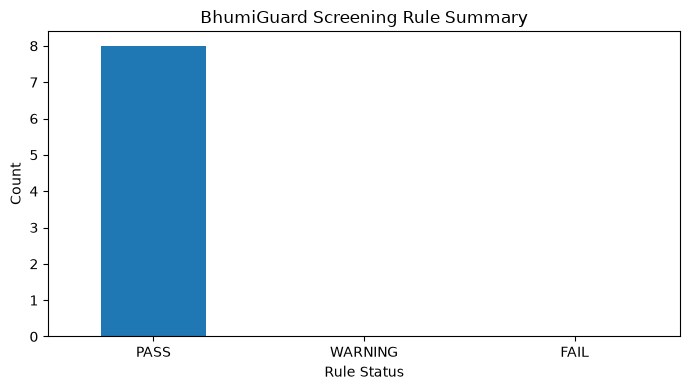

In [33]:
risk_counts = pd.Series(
    {
        "PASS":
            report[
                "pass_count"
            ],

        "WARNING":
            report[
                "warning_count"
            ],

        "FAIL":
            report[
                "fail_count"
            ],
    }
)

plt.figure(
    figsize=(7, 4)
)

risk_counts.plot(
    kind="bar"
)

plt.title(
    "BhumiGuard Screening Rule Summary"
)

plt.xlabel(
    "Rule Status"
)

plt.ylabel(
    "Count"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()

In [34]:
pd.testing.assert_frame_equal(
    ledger_before_pipeline,
    step24_ledger_df
)

print(
    "Ledger unchanged after screening: PASS"
)

Ledger unchanged after screening: PASS


In [35]:
step24_live_test = (
    run_bhumiguard_pipeline(
        record=
            step24_verified_record,

        ledger_df=
            step24_ledger_df,

        history_df=
            step24_history_df,

        mutation_df=
            step24_mutation_df,

        people_df=
            step24_people_df,

        parcels_df=
            step24_parcels_df,

        simulation_mode=
            False,
    )
)

print(
    "Live-mode status:",
    step24_live_test[
        "pipeline_status"
    ]
)

Live-mode status: BLOCKED_DOCUMENT_STATUS


In [36]:
assert (
    step24_result[
        "pipeline_status"
    ]
    ==
    "SIMULATION_COMPLETE"
)

assert (
    report[
        "risk_level"
    ]
    ==
    "LOW"
)

assert (
    report[
        "fail_count"
    ]
    == 0
)

assert (
    report[
        "warning_count"
    ]
    == 0
)

assert (
    step24_result[
        "live_commit_allowed"
    ]
    is False
)

assert (
    step24_live_test[
        "pipeline_status"
    ]
    ==
    "BLOCKED_DOCUMENT_STATUS"
)

assert (
    (
        step24_rules_df[
            "status"
        ]
        == "PASS"
    ).all()
)

print(
    "One-click pipeline safety tests: PASS"
)

One-click pipeline safety tests: PASS


In [37]:
print("STEP 24 SUMMARY")
print("----------------")

print(
    "Verified input ready:",
    step24_result[
        "readiness"
    ][
        "ready"
    ]
)

print(
    "Transaction generated:",
    step24_result[
        "transaction"
    ]
    is not None
)

print(
    "Risk report generated:",
    report
    is not None
)

print(
    "Risk level:",
    report[
        "risk_level"
    ]
)

print(
    "Pass rules:",
    report[
        "pass_count"
    ]
)

print(
    "Warning rules:",
    report[
        "warning_count"
    ]
)

print(
    "Fail rules:",
    report[
        "fail_count"
    ]
)

print(
    "Ledger unchanged:",
    True
)

print(
    "Synthetic live mode blocked:",
    (
        step24_live_test[
            "pipeline_status"
        ]
        ==
        "BLOCKED_DOCUMENT_STATUS"
    )
)

print(
    "\nONE-CLICK BHUMIGUARD PIPELINE: READY"
)

STEP 24 SUMMARY
----------------
Verified input ready: True
Transaction generated: True
Risk report generated: True
Risk level: LOW
Pass rules: 8
Warning rules: 0
Fail rules: 0
Ledger unchanged: True
Synthetic live mode blocked: True

ONE-CLICK BHUMIGUARD PIPELINE: READY
